<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta3gorev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

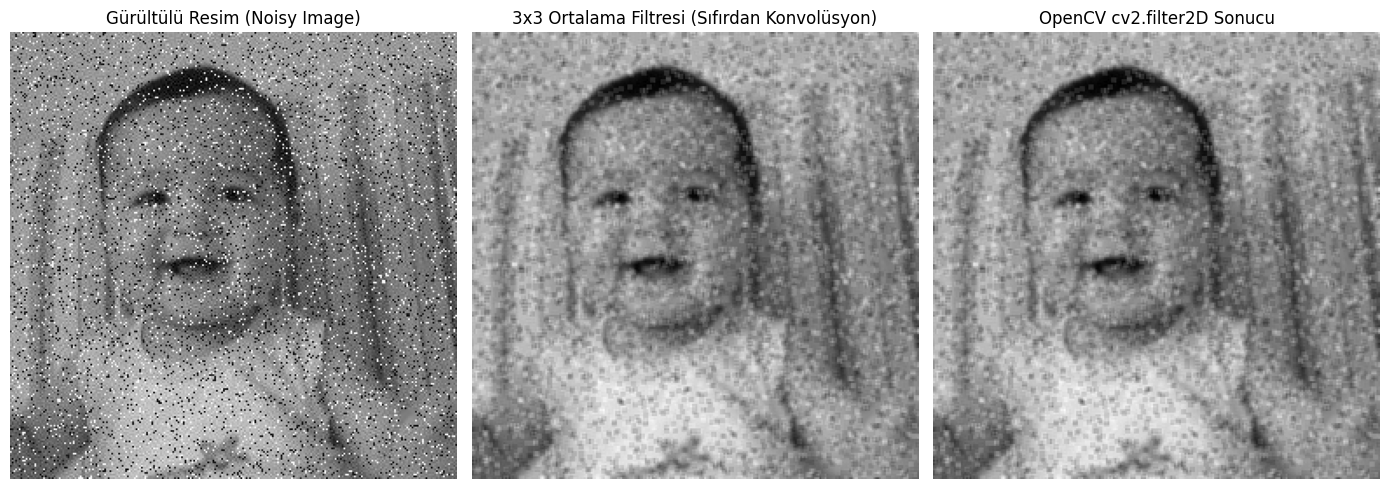

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Konvolüsyon ile Ortalama Filtresinin Sıfırdan Gerçeklenmesi
# -------------------------------------------------------------
def apply_mean_filter_scratch(image):
    """
    3x3 boyutundaki ortalama filtresini konvolüsyon ile uygular.
    """
    h, w = image.shape

    # 3x3 ortalama çekirdeği (Kernel): Tüm elemanlar 1/9
    kernel = np.ones((3, 3), dtype=np.float32) / 9.0

    # Kenar pikselleri için 1 piksellik dolgu (padding)
    # 'reflect' kenar yansıtması kullanarak kenar kararmasını önleriz
    padded_img = np.pad(image, pad_width=1, mode='reflect').astype(np.float32)

    output = np.zeros((h, w), dtype=np.float32)

    # Konvolüsyon döngüsü: Filtreyi resim üzerinde gezdirme
    for i in range(h):
        for j in range(w):
            # 3x3'lük yerel bölgeyi kes
            region = padded_img[i:i+3, j:j+3]

            # Eleman bazlı çarpım ve toplam (Konvolüsyon / Ortalama alma)
            pixel_val = np.sum(region * kernel)
            output[i, j] = pixel_val

    # Değerleri 0-255 aralığına sınırla ve uint8 tipine dönüştür
    output = np.clip(output, 0, 255).astype(np.uint8)
    return output


# -------------------------------------------------------------
# 2. Test ve Çalıştırma
# -------------------------------------------------------------
# Kendi resminizi okuyun (varsa dosya yolunu girin)
noisy_img = cv2.imread('noisy_image.jpg', cv2.IMREAD_GRAYSCALE)

# Eğer resim dosyası yoksa, test için sentetik bir gürültülü resim üretelim:
if noisy_img is None:
    # 512x512 boyutunda örnek gri zemin ve daire
    base_img = np.zeros((512, 512), dtype=np.float32) + 120
    cv2.circle(base_img, (256, 256), 120, 200, -1)

    # Gauss tipi gürültü ekleme
    noise = np.random.normal(0, 25, (512, 512))
    noisy_img = np.clip(base_img + noise, 0, 255).astype(np.uint8)

# A. Sıfırdan yazdığımız konvolüsyon fonksiyonu ile filtreleme
filtered_scratch = apply_mean_filter_scratch(noisy_img)

# B. OpenCV hazır fonksiyonu ile doğrulama (Kıyaslama için)
kernel_cv = np.ones((3, 3), dtype=np.float32) / 9.0
filtered_opencv = cv2.filter2D(noisy_img, -1, kernel_cv)

# -------------------------------------------------------------
# 3. Sonuçların Görselleştirilmesi
# -------------------------------------------------------------
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(noisy_img, cmap='gray')
plt.title('Gürültülü Resim (Noisy Image)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(filtered_scratch, cmap='gray')
plt.title('3x3 Ortalama Filtresi (Sıfırdan Konvolüsyon)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered_opencv, cmap='gray')
plt.title('OpenCV cv2.filter2D Sonucu')
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Konvolüsyon ile Ortalama Filtresinin Sıfırdan Gerçeklenmesi
# -------------------------------------------------------------
def apply_mean_filter_scratch(image):
    """
    3x3 boyutundaki ortalama filtresini konvolüsyon ile uygular.
    """
    h, w = image.shape

    # 3x3 ortalama çekirdeği (Kernel): Tüm elemanlar 1/9
    kernel = np.ones((3, 3), dtype=np.float32) / 9.0

    # Kenar pikselleri için 1 piksellik dolgu (padding)
    # 'reflect' kenar yansıtması kullanarak kenar kararmasını önleriz
    padded_img = np.pad(image, pad_width=1, mode='reflect').astype(np.float32)

    output = np.zeros((h, w), dtype=np.float32)

    # Konvolüsyon döngüsü: Filtreyi resim üzerinde gezdirme
    for i in range(h):
        for j in range(w):
            # 3x3'lük yerel bölgeyi kes
            region = padded_img[i:i+3, j:j+3]

            # Eleman bazlı çarpım ve toplam (Konvolüsyon / Ortalama alma)
            pixel_val = np.sum(region * kernel)
            output[i, j] = pixel_val

    # Değerleri 0-255 aralığına sınırla ve uint8 tipine dönüştür
    output = np.clip(output, 0, 255).astype(np.uint8)
    return output


# -------------------------------------------------------------
# 2. Test ve Çalıştırma
# -------------------------------------------------------------
# Kendi resminizi okuyun (varsa dosya yolunu girin)
noisy_img = cv2.imread('noisy_image.jpg', cv2.IMREAD_GRAYSCALE)

# Eğer resim dosyası yoksa, test için sentetik bir gürültülü resim üretelim:
if noisy_img is None:
    # 512x512 boyutunda örnek gri zemin ve daire
    base_img = np.zeros((512, 512), dtype=np.float32) + 120
    cv2.circle(base_img, (256, 256), 120, 200, -1)

    # Gauss tipi gürültü ekleme
    noise = np.random.normal(0, 25, (512, 512))
    noisy_img = np.clip(base_img + noise, 0, 255).astype(np.uint8)

# A. Sıfırdan yazdığımız konvolüsyon fonksiyonu ile filtreleme
filtered_scratch = apply_mean_filter_scratch(noisy_img)

# B. OpenCV hazır fonksiyonu ile doğrulama (Kıyaslama için)
kernel_cv = np.ones((3, 3), dtype=np.float32) / 9.0
filtered_opencv = cv2.filter2D(noisy_img, -1, kernel_cv)

# -------------------------------------------------------------
# 3. Sonuçların Görselleştirilmesi
# -------------------------------------------------------------
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(noisy_img, cmap='gray')
plt.title('Gürültülü Resim (Noisy Image)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(filtered_scratch, cmap='gray')
plt.title('3x3 Ortalama Filtresi (Sıfırdan Konvolüsyon)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered_opencv, cmap='gray')
plt.title('OpenCV cv2.filter2D Sonucu')
plt.axis('off')

plt.tight_layout()
plt.show()